<a href="https://colab.research.google.com/github/GutenTakJT/Special_repo/blob/main/%ED%91%9C_%ED%86%B5%ED%95%A9%EB%AA%A8%EB%8D%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OneClickAI 표 통합모델
이 노트북은 Google Colab 환경에서 실행하도록 작성되었습니다.
웹앱의 **표 통합모델**과 같은 방법으로 학습합니다.

시트 하나에서 열마다 입력과 출력을 고르고, 출력 열마다 **회귀**(수치)나 **분류**(카테고리)를 정해 한 번에 학습합니다.
카테고리 입력은 원핫으로, 수치 입력은 정규화해서 넣고, 모델은 웹앱과 같은 **MLP**(은닉층 여러 개 + 출력 열마다 헤드)입니다.

**순서**
1. 파일 업로드
2. 열 역할과 종류 정하기
3. 표를 숫자로 바꾸기 (원핫과 정규화)
4. 모델 학습 (MLP + 출력 열마다 헤드)
5. 결과 확인 및 예측

## 1. 파일 업로드

엑셀 파일(`.xlsx`)을 업로드해 주세요. 두 가지 모양을 읽습니다.

- **시트 하나**: 웹앱의 `데이터 저장(.xlsx)` 버튼으로 받은 파일입니다. 첫 행은 열 이름, 첫 열은 항목(이름)입니다.
- **원인/결과 두 시트**: 표 분류, 표 회귀 페이지의 엑셀입니다. 두 시트를 행 순서대로 옆으로 붙이고, 결과 시트에서 온 열을 출력으로 둡니다.
  결과 시트가 0/1 열 여러 개(원핫)면 웹앱처럼 열마다 따로 분류합니다 (승리, 무승부, 패배를 각각 0/1 로 맞힙니다).

웹앱은 행을 999개, 열을 20개까지 쓰지만 이 노트북에는 제한이 없습니다.

In [1]:
# ==========================================
# 불러오기
# ==========================================
import math
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from google.colab import files

# ==========================================
# 파일 업로드
# ==========================================
print('데이터 파일(.xlsx)을 업로드 해주세요.\n')
uploaded = files.upload()

if len(uploaded.keys()) == 0:
    raise ValueError('파일이 업로드되지 않았습니다.')

DATA_FILE_PATH = list(uploaded.keys())[0]

if not DATA_FILE_PATH.endswith(('.xls', '.xlsx')):
    raise ValueError('지원하지 않는 파일 형식입니다. .xlsx 파일을 업로드 해주세요.')


# ==========================================
# 칸 값 다루기 (웹앱과 같은 규칙)
# ==========================================
def is_blank(value):
    if value is None:
        return True
    if isinstance(value, float) and math.isnan(value):
        return True
    return isinstance(value, str) and value.strip() == ''


def js_number(n):
    """숫자를 웹앱(자바스크립트)과 같은 글자로 쓴다. 1.0 은 '1'"""
    n = float(n)
    if n.is_integer() and abs(n) < 1e21:
        return str(int(n))
    return repr(n)


def js_string(value):
    """칸 값을 자바스크립트의 String(값) 처럼 글자로 바꾼다"""
    if value is None:
        return ''
    if isinstance(value, (bool, np.bool_)):
        return 'true' if value else 'false'
    if isinstance(value, (int, float, np.integer, np.floating)):
        return js_number(value) if math.isfinite(value) else ''
    if hasattr(value, 'strftime'):   # 엑셀의 날짜 칸
        return value.strftime('%Y-%m-%d')
    return str(value)


def to_cell_string(value):
    """칸 값을 비교용 글자로: NFC, 대시 통일, 앞뒤 공백 제거"""
    text = unicodedata.normalize('NFC', js_string(value))
    for dash in '–—−':
        text = text.replace(dash, '-')
    return text.strip()


def parse_number(value):
    """숫자로 읽히면 float, 아니면 None"""
    text = to_cell_string(value)
    if text == '' or '_' in text:
        return None
    try:
        n = float(text)
    except ValueError:
        return None
    return n if math.isfinite(n) else None


def read_table(frame):
    """시트를 [행][칸] 목록으로. 빈 행은 빼고, 열은 머리글이 있는 곳까지만 둔다"""
    table = [list(row) for row in frame.values.tolist()]
    table = [row for row in table if not all(is_blank(v) for v in row)]
    if not table:
        raise ValueError('시트에 데이터가 없습니다.')
    filled = [i for i, v in enumerate(table[0]) if not is_blank(v)]
    if not filled:
        raise ValueError('첫 행(머리글)에 열 이름이 없습니다.')
    width = filled[-1] + 1
    return [row[:width] + [None] * (width - len(row)) for row in table]


# ==========================================
# 엑셀 읽기
# ==========================================
sheets = pd.read_excel(DATA_FILE_PATH, sheet_name=None, header=None, dtype=object)
merged_output_count = 0   # 원인/결과를 붙였을 때 결과 시트에서 온 열 개수

if '원인' in sheets and '결과' in sheets:
    cause = read_table(sheets['원인'])
    result = read_table(sheets['결과'])
    if len(cause) != len(result):
        raise ValueError(f"'원인' 시트({len(cause) - 1}행)와 '결과' 시트({len(result) - 1}행)의 행 수가 다릅니다.")
    cols = cause[0] + result[0][1:]
    rows = [c + r[1:] for c, r in zip(cause[1:], result[1:])]
    merged_output_count = len(result[0]) - 1
    print("'원인' 시트와 '결과' 시트를 행 순서대로 붙였습니다. 결과 시트에서 온 열은 출력입니다.")
else:
    sheet_name = '데이터' if '데이터' in sheets else list(sheets.keys())[0]
    table = read_table(sheets[sheet_name])
    cols, rows = table[0], table[1:]
    print(f"'{sheet_name}' 시트를 읽었습니다.")

if is_blank(cols[0]):
    cols[0] = '항목'

column_names = [to_cell_string(c) or f'열 {i}' for i, c in enumerate(cols)]
print(f'\n행 {len(rows)}개, 열 {len(cols)}개: {column_names}')
display(pd.DataFrame(rows[:5], columns=column_names))

데이터 파일(.xlsx)을 업로드 해주세요.



Saving GSW 경기 3점슛 성공개수 예측 (1).xlsx to GSW 경기 3점슛 성공개수 예측 (1).xlsx
'데이터' 시트를 읽었습니다.

행 820개, 열 8개: ['시즌', '홈_원정', '어시스트', '야투율', '자유투_시도', '턴오버', '승패', '3점슛_성공']


,시즌,홈_원정,어시스트,야투율,자유투_시도,턴오버,승패,3점슛_성공
0,2014-15,H,32,0.435,23,17,W,14
1,2014-15,H,32,0.501,19,15,W,11
2,2014-15,H,32,0.469,26,11,W,13
3,2014-15,H,35,0.485,17,15,W,15
4,2014-15,H,22,0.593,19,14,L,11


## 2. 열 역할과 종류 정하기

열마다 **역할**(입력/출력/제외)과 **종류**(카테고리/수치)를 정합니다.
아래 설정을 비워 두면 웹앱과 같은 규칙으로 자동으로 정합니다.

- 마지막 열은 **출력**, 나머지 열은 **입력** (원인/결과 파일은 결과 시트에서 온 열이 출력)
- 숫자가 아닌 열은 **카테고리**, 숫자 열은 정수이면서 종류가 5개 이하면 **카테고리**, 아니면 **수치**
- 입력 열은 카테고리면 원핫, 수치면 정규화해서 넣습니다
- 출력 열은 카테고리면 **분류**(Softmax), 수치면 **회귀**(Linear)로 배웁니다. 출력이 여러 개면 헤드가 여러 개인 모델 하나로 한꺼번에 배웁니다

웹앱에서 받은 파일에는 열 설정이 들어 있지 않습니다. 웹앱에서 바꾼 설정(예: 1~5 점수를 회귀로)은 아래 칸에 다시 적어 주세요.

In [2]:
# ==========================================
# 열 설정 (비워 두면 웹앱과 같은 규칙으로 자동으로 정합니다)
# ==========================================
INPUT_COLUMNS = []           # 입력으로 쓸 열 이름. 예: ['요일', '날씨', '기온']
OUTPUT_COLUMNS = []          # 출력으로 쓸 열 이름. 예: ['매출(천원)', '혼잡도']
KIND_OVERRIDES = {}          # 종류 바꾸기. 'categorical' 은 카테고리(분류), 'numeric' 은 수치(회귀). 예: {'별점': 'numeric'}
NORMALIZATION = 'minMax11'   # 수치 열 정규화: 'none', 'minMax01'(0~1), 'minMax11'(-1~1, 기본), 'zScore'

# ==========================================
# 웹앱과 같은 기준값
# ==========================================
MAX_CATEGORIES = 50          # 카테고리 열 하나의 종류 최대 개수
CATEGORICAL_UNIQUE_MAX = 5   # 정수이면서 종류가 이 개수 이하이면 카테고리로 추정

KIND_LABELS = {'categorical': '카테고리', 'numeric': '수치'}
ROLE_LABELS = {'input': '입력', 'output': '출력', 'exclude': '제외'}


def analyze_columns(cols, rows):
    """열마다 값을 훑어 숫자인지, 서로 다른 값, 최소/최대/평균/표준편차를 센다 (항목 열은 뺀다)"""
    stats = []
    for c in range(1, len(cols)):
        cells, numbers = [], []
        is_numeric = is_integer = True
        empty = 0
        for row in rows:
            raw = row[c] if c < len(row) else None
            s = to_cell_string(raw)
            if s == '':
                empty += 1
                continue
            cells.append(s)
            n = parse_number(s)
            if n is None:
                is_numeric = is_integer = False
            else:
                if not n.is_integer():
                    is_integer = False
                numbers.append(n)
        if not numbers:
            is_numeric = is_integer = False

        # 서로 다른 값 (분류의 종류). 숫자 열은 1 과 1.0 을 같은 값으로 보고 크기 순서로 둔다
        unique, seen = [], set()
        for s in cells:
            key = js_number(parse_number(s)) if is_numeric else s
            if key not in seen:
                seen.add(key)
                unique.append(key)
        if is_numeric:
            unique.sort(key=float)

        mean = sum(numbers) / len(numbers) if numbers else None
        std = math.sqrt(max(sum(n * n for n in numbers) / len(numbers) - mean ** 2, 0)) if numbers else None
        suggested = 'categorical' if (not is_numeric or (is_integer and len(unique) <= CATEGORICAL_UNIQUE_MAX)) else 'numeric'
        stats.append({
            'index': c,
            'name': column_names[c],
            'is_numeric': is_numeric,
            'unique': unique,
            'empty': empty,
            'min': min(numbers) if numbers else None,
            'max': max(numbers) if numbers else None,
            'mean': mean,
            'std': std,
            'suggested': suggested,
        })
    return stats


stats = analyze_columns(cols, rows)
by_name = {s['name']: s for s in stats}

# ==========================================
# 자동 역할과 종류
# ==========================================
first_output = len(cols) - merged_output_count if merged_output_count else len(cols) - 1
for s in stats:
    s['kind'] = s['suggested']
    s['role'] = 'output' if s['index'] >= first_output else 'input'

# ==========================================
# 직접 적은 설정 반영
# ==========================================
for name in list(INPUT_COLUMNS) + list(OUTPUT_COLUMNS) + list(KIND_OVERRIDES):
    if name not in by_name:
        raise ValueError(f"'{name}' 열이 없습니다. 열 이름: {column_names[1:]}")
if INPUT_COLUMNS:
    for s in stats:
        if s['name'] in INPUT_COLUMNS:
            s['role'] = 'input'
        elif s['role'] == 'input':
            s['role'] = 'exclude'
if OUTPUT_COLUMNS:
    for s in stats:
        if s['name'] in OUTPUT_COLUMNS:
            s['role'] = 'output'
        elif s['role'] == 'output':
            s['role'] = 'exclude'
for name, kind in KIND_OVERRIDES.items():
    if kind not in ('categorical', 'numeric'):
        raise ValueError(f"'{name}' 의 종류는 'categorical' 이나 'numeric' 으로 적어 주세요.")
    if kind == 'numeric' and not by_name[name]['is_numeric']:
        raise ValueError(f"'{name}' 열에 숫자가 아닌 값이 있어 수치로 쓸 수 없습니다.")
    by_name[name]['kind'] = kind

# ==========================================
# 검사 (웹앱과 같은 조건)
# ==========================================
input_specs = [s for s in stats if s['role'] == 'input']
output_specs = [s for s in stats if s['role'] == 'output']
if not input_specs:
    raise ValueError('입력으로 쓸 열이 없습니다. INPUT_COLUMNS 에 적어 주세요.')
if not output_specs:
    raise ValueError('출력으로 쓸 열이 없습니다. OUTPUT_COLUMNS 에 적어 주세요.')
for s in input_specs + output_specs:
    if s['empty']:
        raise ValueError(f"'{s['name']}' 열에 빈칸이 {s['empty']}개 있습니다. 채우거나 빈 행을 지워 주세요.")
for s in input_specs:
    if s['kind'] == 'categorical' and len(s['unique']) > MAX_CATEGORIES:
        raise ValueError(f"'{s['name']}' 열의 종류가 {len(s['unique'])}개로 너무 많습니다. 제외하거나 수치로 바꿔 주세요. (최대 {MAX_CATEGORIES}개)")
    if len(s['unique']) <= 1:
        raise ValueError(f"'{s['name']}' 열은 값이 한 가지뿐이라 학습에 도움이 되지 않습니다. 제외해 주세요.")
for s in output_specs:
    if s['kind'] == 'numeric':
        if not s['is_numeric']:
            raise ValueError(f"'{s['name']}' 열에 숫자가 아닌 값이 있어 회귀로 쓸 수 없습니다. 분류로 바꿔 주세요.")
        if s['min'] == s['max']:
            raise ValueError(f"'{s['name']}' 열의 값이 모두 같아 회귀 학습을 할 수 없습니다.")
    else:
        if len(s['unique']) < 2:
            raise ValueError(f"'{s['name']}' 열에 종류가 두 개 이상 있어야 분류할 수 있습니다.")
        if len(s['unique']) > MAX_CATEGORIES:
            raise ValueError(f"'{s['name']}' 열의 종류가 {len(s['unique'])}개로 너무 많습니다. (최대 {MAX_CATEGORIES}개)")


def learning_of(s):
    if s['role'] == 'input':
        return '원핫 입력' if s['kind'] == 'categorical' else '정규화 입력'
    if s['role'] == 'output':
        return '분류 (Softmax)' if s['kind'] == 'categorical' else '회귀 (Linear)'
    return '-'


def preview_of(s):
    if s['kind'] == 'categorical':
        return f"{len(s['unique'])}종류: " + ', '.join(s['unique'][:4]) + (f" 외 {len(s['unique']) - 4}개" if len(s['unique']) > 4 else '')
    return f"{s['min']:g} ~ {s['max']:g} (평균 {s['mean']:.2f})"


display(pd.DataFrame([{
    '열': s['name'],
    '역할': ROLE_LABELS[s['role']],
    '종류': KIND_LABELS[s['kind']],
    '학습': learning_of(s),
    '값 미리보기': preview_of(s),
} for s in stats]))

,열,역할,종류,학습,값 미리보기
0,홈_원정,입력,카테고리,원핫 입력,"2종류: H, A"
1,어시스트,입력,수치,정규화 입력,12 ~ 42 (평균 28.38)
2,야투율,입력,수치,정규화 입력,0.373 ~ 0.593 (평균 0.48)
3,자유투_시도,입력,수치,정규화 입력,5 ~ 37 (평균 20.44)
4,턴오버,입력,수치,정규화 입력,6 ~ 23 (평균 14.07)
5,승패,입력,카테고리,원핫 입력,"2종류: W, L"
6,3점슛_성공,출력,수치,회귀 (Linear),4 ~ 24 (평균 13.96)


## 3. 표를 숫자로 바꾸기 (원핫과 정규화)

- 카테고리 열은 **원핫**(종류마다 한 칸, 해당 종류만 1)으로, 수치 열은 설정한 방식으로 **정규화**(기본 -1~1, 표 전체의 최솟값과 최댓값)합니다.
  회귀 출력은 예측할 때 원래 단위로 되돌립니다.
- 입력 벡터는 입력 열의 벡터를 순서대로 이어 붙인 것이고, 출력은 헤드마다 따로 둡니다 (분류는 원핫, 회귀는 값 하나).
- 행 순서는 웹앱과 같은 시드(13)로 섞고, 뒤쪽 20%를 검증에 씁니다. 20행 미만이면 검증 없이 모두 학습합니다.
  케라스의 `validation_split`도 뒤쪽 행을 그대로 떼므로 웹앱과 같은 행이 검증이 됩니다.

In [3]:
# ==========================================
# 인코더: 수치는 정규화, 카테고리는 원핫
# ==========================================
def build_encoder(spec):
    if spec['kind'] == 'categorical':
        return {'index': spec['index'], 'name': spec['name'], 'kind': 'categorical', 'categories': list(spec['unique'])}
    return {
        'index': spec['index'], 'name': spec['name'], 'kind': 'numeric', 'normalization': NORMALIZATION,
        'min': spec['min'], 'max': spec['max'], 'mean': spec['mean'], 'std': spec['std'],
    }


def normalize(value, enc):
    lo, hi, method = enc['min'], enc['max'], enc['normalization']
    if method == 'none':
        return value
    if method == 'minMax01':
        return 0 if hi == lo else (value - lo) / (hi - lo)
    if method == 'zScore':
        return 0 if enc['std'] == 0 else (value - enc['mean']) / enc['std']
    return 0 if hi == lo else (value - lo) / (hi - lo) * 2 - 1


def denormalize(value, enc):
    lo, hi, method = enc['min'], enc['max'], enc['normalization']
    if method == 'none':
        return value
    if method == 'minMax01':
        return lo if hi == lo else value * (hi - lo) + lo
    if method == 'zScore':
        return enc['mean'] if enc['std'] == 0 else value * enc['std'] + enc['mean']
    return lo if hi == lo else (value + 1) / 2 * (hi - lo) + lo


def encode_value(enc, raw):
    """칸 하나를 벡터로. 수치는 정규화한 값 하나, 카테고리는 원핫. 못 읽으면 None"""
    text = to_cell_string(raw)
    if enc['kind'] == 'numeric':
        n = parse_number(text)
        return None if n is None else [normalize(n, enc)]
    categories = enc['categories']
    index = categories.index(text) if text in categories else -1
    if index == -1 and parse_number(text) is not None:
        key = js_number(parse_number(text))   # 숫자 카테고리는 1 과 1.0 을 같은 칸으로 본다
        index = next((k for k, c in enumerate(categories) if parse_number(c) is not None and js_number(parse_number(c)) == key), -1)
    if index == -1:
        return None
    vector = [0.0] * len(categories)
    vector[index] = 1.0
    return vector


def encoder_dim(enc):
    return len(enc['categories']) if enc['kind'] == 'categorical' else 1


def shuffle_order(n, seed=13):
    """웹앱과 같은 시드 고정 셔플 (mulberry32 + Fisher-Yates). 32비트 정수 연산을 그대로 옮겼다"""
    order = list(range(n))
    a = seed & 0xFFFFFFFF

    def rand():
        nonlocal a
        a = (a + 0x6D2B79F5) & 0xFFFFFFFF
        t = ((a ^ (a >> 15)) * (a | 1)) & 0xFFFFFFFF
        t ^= (t + (((t ^ (t >> 7)) * (t | 61)) & 0xFFFFFFFF)) & 0xFFFFFFFF
        return ((t ^ (t >> 14)) & 0xFFFFFFFF) / 4294967296

    for i in range(n - 1, 0, -1):
        j = int(rand() * (i + 1))
        order[i], order[j] = order[j], order[i]
    return order


input_encoders = [build_encoder(s) for s in input_specs]
output_encoders = [build_encoder(s) for s in output_specs]
INPUT_DIM = sum(encoder_dim(e) for e in input_encoders)
OUTPUT_DIM = sum(encoder_dim(e) for e in output_encoders)


def encode_row(encoders, row, r):
    vector = []
    for enc in encoders:
        part = encode_value(enc, row[enc['index']])
        if part is None:
            raise ValueError(f"{r + 1}번째 행의 '{enc['name']}' 값을 읽을 수 없습니다.")
        vector.extend(part)
    return vector


n_rows = len(rows)
X = np.array([encode_row(input_encoders, row, r) for r, row in enumerate(rows)], dtype='float32')   # [행, INPUT_DIM]
Y_heads = [np.array([encode_row([enc], row, r) for r, row in enumerate(rows)], dtype='float32') for enc in output_encoders]

# 웹앱과 같은 순서로 섞는다. 케라스의 validation_split 은 뒤쪽 행을 그대로 떼어 검증에 쓴다
order = shuffle_order(n_rows)
X = X[order]
Y_heads = [y[order] for y in Y_heads]
VALIDATION_SPLIT = 0.2 if n_rows >= 20 else 0.0
train_count = math.floor(n_rows * (1 - VALIDATION_SPLIT))

for enc in input_encoders:
    if enc['kind'] == 'categorical':
        print(f"[입력 {enc['name']}] 원핫 {len(enc['categories'])}종류: {enc['categories'][:6]}{' ...' if len(enc['categories']) > 6 else ''}")
    else:
        print(f"[입력 {enc['name']}] 값 {enc['min']:g} ~ {enc['max']:g}, 정규화 {enc['normalization']}")
for enc in output_encoders:
    if enc['kind'] == 'categorical':
        print(f"[출력 {enc['name']}] 분류 {len(enc['categories'])}종류: {enc['categories']}")
    else:
        print(f"[출력 {enc['name']}] 회귀, 값 {enc['min']:g} ~ {enc['max']:g}, 정규화 {enc['normalization']}")
print(f'\n입력 {INPUT_DIM}차원, 출력 {OUTPUT_DIM}차원, 학습 {train_count}행, 검증 {n_rows - train_count}행')

[입력 홈_원정] 원핫 2종류: ['H', 'A']
[입력 어시스트] 값 12 ~ 42, 정규화 minMax11
[입력 야투율] 값 0.373 ~ 0.593, 정규화 minMax11
[입력 자유투_시도] 값 5 ~ 37, 정규화 minMax11
[입력 턴오버] 값 6 ~ 23, 정규화 minMax11
[입력 승패] 원핫 2종류: ['W', 'L']
[출력 3점슛_성공] 회귀, 값 4 ~ 24, 정규화 minMax11

입력 8차원, 출력 1차원, 학습 656행, 검증 164행


## 4. 모델 학습 (MLP + 출력 열마다 헤드)

웹앱과 같은 구조입니다.

- 입력 `INPUT_DIM`차원 → Dense(노드 수, ReLU) `NUM_LAYERS`층 → 출력 열마다 헤드 하나.
  분류는 Softmax + categorical crossentropy, 회귀는 Linear + MSE이고, 전체 loss는 헤드 loss의 합입니다.
- 은닉 노드 하나는 `h = ReLU(w1 x1 + w2 x2 + ... + b)` 입니다. 파라미터는 층마다 `(앞 층 차원 + 1) × 노드 수`, 헤드는 `(노드 수 + 1) × 출력 차원`입니다.
- 노드 수 자동은 `(입력 차원 + 출력 차원) × 2`를 32~128 사이로 맞춘 값입니다 (웹앱과 같다).
- Adam, 학습률 0.001, 배치 16, 100번 학습, 은닉층 3층, 조기 종료는 끕니다 (웹앱 기본값).
  조기 종료를 켜면 검증 loss가 `PATIENCE`번 나아지지 않을 때 멈춥니다. 20행 미만이면 검증 데이터가 없어 끝까지 돕니다.

In [4]:
# ==========================================
# 학습 설정 (웹앱 톱니바퀴 기본값)
# ==========================================
NUM_LAYERS = 3             # 은닉층 수 (선택지 1~4)
NUM_NODES = 0              # 노드 수 (0 = 자동. 선택지 8, 16, 32, 64, 128, 256, 512)
EPOCHS = 100
BATCH_SIZE = 16
LEARNING_RATE = 0.001
EARLY_STOPPING = False     # 검증 데이터가 있을 때만 걸린다 (웹앱 기본값은 끔)
PATIENCE = 50


def auto_nodes(input_dim, output_dim):
    return min(max((input_dim + output_dim) * 2, 32), 128)


units = auto_nodes(INPUT_DIM, OUTPUT_DIM) if NUM_NODES == 0 else NUM_NODES

# ==========================================
# 모델: 은닉층들 + 출력 열마다 헤드 (웹앱의 buildUnifiedModel 과 같다)
# ==========================================
inputs = keras.Input(shape=(INPUT_DIM,), name='features')
x = inputs
for i in range(NUM_LAYERS):
    x = keras.layers.Dense(units, activation='relu', name=f'hidden_{i}')(x)

outputs, losses = [], []
for k, enc in enumerate(output_encoders):
    categorical = enc['kind'] == 'categorical'
    outputs.append(keras.layers.Dense(encoder_dim(enc), activation='softmax' if categorical else 'linear', name=f'head_{k}')(x))
    losses.append('categorical_crossentropy' if categorical else 'mean_squared_error')

single_head = len(outputs) == 1
model = keras.Model(inputs, outputs[0] if single_head else outputs)
model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss=losses[0] if single_head else losses)
model.summary()
for k, enc in enumerate(output_encoders):
    print(f"head_{k}: {enc['name']} ({'분류' if enc['kind'] == 'categorical' else '회귀'})")

# 파라미터 수 (웹앱의 그림과 같은 식)
expected, prev = 0, INPUT_DIM
for i in range(NUM_LAYERS):
    expected += (prev + 1) * units
    prev = units
expected += (prev + 1) * OUTPUT_DIM
print(f'\n파라미터 {model.count_params():,}개 (식으로 센 값 {expected:,}개), 약 {model.count_params() * 4 / 1024:.1f}KB')

callbacks = []
if EARLY_STOPPING and VALIDATION_SPLIT > 0:
    callbacks.append(keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True, verbose=1))

# ==========================================
# 학습
# ==========================================
history = model.fit(
    X,
    Y_heads[0] if single_head else Y_heads,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    shuffle=True,
    callbacks=callbacks,
    verbose=2,
)

# ==========================================
# 모델 저장
# ==========================================
model.save('table_unified_model.keras')

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_0 (Dense)                │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_0 (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,433 (9.50 KB)

 Trainable params: 2,433 (9.50 KB)

 Non-trainable params: 0 (0.00 B)

head_0: 3점슛_성공 (회귀)

파라미터 2,433개 (식으로 센 값 2,433개), 약 9.5KB
Epoch 1/100
41/41 - 1s - 33ms/step - loss: 0.1168 - val_loss: 0.1301
Epoch 2/100
41/41 - 0s - 4ms/step - loss: 0.1126 - val_loss: 0.1301
Epoch 3/100
41/41 - 0s - 4ms/step - loss: 0.1107 - val_loss: 0.1316
Epoch 4/100
41/41 - 0s - 8ms/step - loss: 0.1101 - val_loss: 0.1280
Epoch 5/100
41/41 - 0s - 4ms/step - loss: 0.1084 - val_loss: 0.1288
Epoch 6/100
41/41 - 0s - 4ms/step - loss: 0.1072 - val_loss: 0.1281
Epoch 7/100
41/41 - 0s - 4ms/step - loss: 0.1063 - val_loss: 0.1277
Epoch 8/100
41/41 - 0s - 4ms/step - loss: 0.1057 - val_loss: 0.1280
Epoch 9/100
41/41 - 0s - 4ms/step - loss: 0.1052 - val_loss: 0.1288
Epoch 10/100
41/41 - 0s - 4ms/step - loss: 0.1037 - val_loss: 0.1303
Epoch 11/100
41/41 - 0s - 4ms/step - loss: 0.1036 - val_loss: 0.1319
Epoch 12/100
41/41 - 0s - 4ms/step - loss: 0.1027 - val_loss: 0.1294
Epoch 13/100
41/41 - 0s - 4ms/step - loss: 0.1016 - val_loss: 0.1302
Epoch 14/100
41/41 - 0s - 4ms/step - loss: 0.1012 - 

## 5. 결과 확인 및 예측

학습 손실 그래프를 그리고, 검증 데이터로 출력 열마다 정확도(분류)나 평균 오차(회귀)를 봅니다.
마지막 칸에서 직접 값을 넣어 예측해 보세요. 카테고리 열은 표에 있던 종류 중 하나를, 수치 열은 숫자를 적습니다.

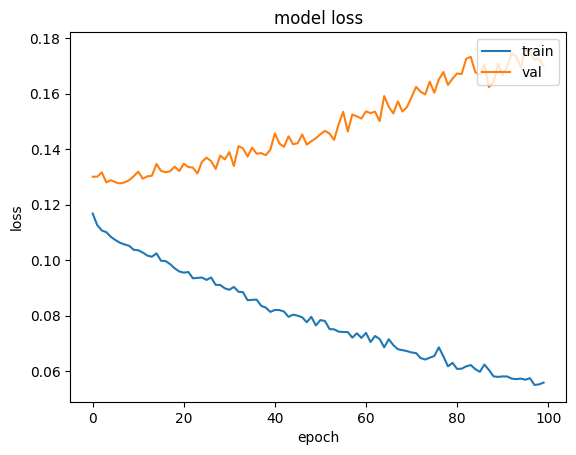

검증 데이터 164행 (학습에 쓰지 않은 행)

[3점슛_성공] 회귀 평균 오차(MAE): 3.332


In [5]:
# ==========================================
# 모델 결과 확인 (그래프)
# ==========================================
plt.plot(history.history['loss'])
legend = ['train']
if 'val_loss' in history.history:
    plt.plot(history.history['val_loss'])
    legend.append('val')
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(legend, loc='upper right')
plt.show()

# ==========================================
# 출력 열마다 성능 보기
# ==========================================
if VALIDATION_SPLIT > 0:
    X_check, Y_check = X[train_count:], [y[train_count:] for y in Y_heads]
    print(f'검증 데이터 {n_rows - train_count}행 (학습에 쓰지 않은 행)\n')
else:
    X_check, Y_check = X, Y_heads
    print(f'학습 데이터 {n_rows}행 (행이 20개 미만이라 검증 데이터가 없습니다)\n')

pred = model.predict(X_check, verbose=0)
if single_head:
    pred = [pred]
for enc, p, y in zip(output_encoders, pred, Y_check):
    if enc['kind'] == 'categorical':
        accuracy = float(np.mean(np.argmax(p, axis=1) == np.argmax(y, axis=1)))
        print(f"[{enc['name']}] 분류 정확도: {accuracy * 100:.1f}%")
    else:
        predicted = np.array([denormalize(float(v), enc) for v in p[:, 0]])
        actual = np.array([denormalize(float(v), enc) for v in y[:, 0]])
        print(f"[{enc['name']}] 회귀 평균 오차(MAE): {np.mean(np.abs(predicted - actual)):.3f}")

In [6]:
# ==========================================
# 직접 값을 넣어 예측하기
# ==========================================
def predict(values):
    """values: {입력 열 이름: 값}. 웹앱 예측 화면처럼 출력 열마다 결과를 보여 준다"""
    vector = []
    for enc in input_encoders:
        raw = values.get(enc['name'], '')
        part = encode_value(enc, raw)
        if part is None:
            if enc['kind'] == 'categorical':
                raise ValueError(f"'{enc['name']}' 값 '{raw}' 은(는) 표에 없던 종류입니다. 다음 중 하나를 적어 주세요: {enc['categories']}")
            raise ValueError(f"'{enc['name']}' 에는 숫자를 적어 주세요. (지금 값: {raw!r})")
        vector.extend(part)
        print(f"[{enc['name']}] {to_cell_string(raw)}")

    result = model.predict(np.array([vector], dtype='float32'), verbose=0)
    if single_head:
        result = [result]
    print()
    for enc, p in zip(output_encoders, result):
        p = p[0]
        if enc['kind'] == 'categorical':
            ranked = sorted(zip(enc['categories'], p), key=lambda item: -item[1])
            print(f"[{enc['name']}] " + ', '.join(f'{label} {prob * 100:.1f}%' for label, prob in ranked))
        else:
            print(f"[{enc['name']}] {denormalize(float(p[0]), enc):.2f}")


# 기본값은 웹앱 예측 화면과 같다: 카테고리는 첫 종류, 수치는 평균. 원하는 값으로 바꿔 보세요.
my_values = {
    enc['name']: (enc['categories'][0] if enc['kind'] == 'categorical' else round(enc['mean'], 2))
    for enc in input_encoders
}
# my_values = {'요일': '토', '날씨': '맑음', '기온': 28.5, '할인': 1}
predict(my_values)

[홈_원정] H
[어시스트] 28.38
[야투율] 0.48
[자유투_시도] 20.44
[턴오버] 14.07
[승패] W

[3점슛_성공] 14.70
